Implement sentiment analysis using Logistic regression,  LSTM, and Vanilla Transformer models and BERT pretrained model on IMDB Movie Reviews Dataset and perform comparative analysis among all the models.

In [6]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torch.nn.utils.rnn import pad_sequence
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

# Load dataset
dataset_path = "/content/drive/MyDrive/CNLP-Lab/Experiment-7/IMDB-Dataset.csv"
if os.path.exists(dataset_path):
    df = pd.read_csv(dataset_path)
else:
    # Fallback to online sample if not found in path
    print("File not found. Loading online IMDB sample.")
    df = pd.read_csv("https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv")

# Encode label
df['label'] = df['sentiment'].map({'positive': 1, 'negative': 0})

# For training speed within Colab, we sample a subset
df_sample = df.sample(n=3000, random_state=42).reset_index(drop=True)

train_df, test_df = train_test_split(df_sample, test_size=0.2, random_state=42)
print(f"Loaded dataset. Train shape: {train_df.shape}, Test shape: {test_df.shape}")

Loaded dataset. Train shape: (2400, 3), Test shape: (600, 3)


In [7]:
# Model 1: Logistic Regression with TF-IDF
vectorizer = TfidfVectorizer(max_features=5000, stop_words='english')
X_train_tfidf = vectorizer.fit_transform(train_df['review'])
X_test_tfidf = vectorizer.transform(test_df['review'])

y_train = train_df['label'].values
y_test = test_df['label'].values

lr_model = LogisticRegression()
lr_model.fit(X_train_tfidf, y_train)
y_pred_lr = lr_model.predict(X_test_tfidf)

lr_precision, lr_recall, lr_f1, _ = precision_recall_fscore_support(y_test, y_pred_lr, average='binary')
lr_acc = accuracy_score(y_test, y_pred_lr)

print("=== Logistic Regression Results ===")
print(classification_report(y_test, y_pred_lr))

=== Logistic Regression Results ===
              precision    recall  f1-score   support

           0       0.86      0.83      0.84       292
           1       0.84      0.87      0.85       308

    accuracy                           0.85       600
   macro avg       0.85      0.85      0.85       600
weighted avg       0.85      0.85      0.85       600



In [8]:
# Tokenizer and Dataset helper for PyTorch Models (LSTM & Transformer)
class Vocabulary:
    def __init__(self, max_vocab_size=10000):
        self.max_vocab_size = max_vocab_size
        self.word2idx = {'<pad>': 0, '<unk>': 1}
        self.idx2word = {0: '<pad>', 1: '<unk>'}

    def fit(self, texts):
        word_counts = Counter(word for text in texts for word in text.lower().split())
        most_common = word_counts.most_common(self.max_vocab_size - 2)
        for i, (word, _) in enumerate(most_common):
            self.word2idx[word] = i + 2
            self.idx2word[i + 2] = word

    def transform(self, text):
        return [self.word2idx.get(word, 1) for word in text.lower().split()]

vocab = Vocabulary()
vocab.fit(train_df['review'])

class IMDBDataset(Dataset):
    def __init__(self, df, vocab, max_len=150):
        self.labels = df['label'].values
        self.sequences = [vocab.transform(text)[:max_len] for text in df['review']]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return torch.tensor(self.sequences[idx], dtype=torch.long), torch.tensor(self.labels[idx], dtype=torch.float)

def pad_collate(batch):
    sequences, labels = zip(*batch)
    padded_seqs = pad_sequence(sequences, batch_first=True, padding_value=0)
    return padded_seqs, torch.tensor(labels)

train_ds = IMDBDataset(train_df, vocab)
test_ds = IMDBDataset(test_df, vocab)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, collate_fn=pad_collate)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, collate_fn=pad_collate)

In [13]:
# Model 2: LSTM from Scratch
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128):
        super(LSTMClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True, num_layers=1, bidirectional=False)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        embedded = self.embedding(x)
        _, (hidden, _) = self.lstm(embedded)
        return torch.sigmoid(self.fc(hidden[-1])).squeeze()

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
lstm_model = LSTMClassifier(len(vocab.word2idx)).to(device)
criterion = nn.BCELoss()
optimizer = optim.Adam(lstm_model.parameters(), lr=0.005)

# Train LSTM
lstm_model.train()
for epoch in range(5):
    for seqs, labels in train_loader:
        seqs, labels = seqs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = lstm_model(seqs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

# Evaluate LSTM
lstm_model.eval()
y_pred_lstm = []
with torch.no_grad():
    for seqs, _ in test_loader:
        seqs = seqs.to(device)
        preds = (lstm_model(seqs) > 0.5).cpu().long().tolist()
        # Handle scalar output in small final batch
        if isinstance(preds, int): preds = [preds]
        y_pred_lstm.extend(preds)

lstm_precision, lstm_recall, lstm_f1, _ = precision_recall_fscore_support(y_test, y_pred_lstm, average='binary')
lstm_acc = accuracy_score(y_test, y_pred_lstm)
print("=== LSTM Results ===")
print(classification_report(y_test, y_pred_lstm))

=== LSTM Results ===
              precision    recall  f1-score   support

           0       0.52      0.27      0.36       292
           1       0.53      0.76      0.62       308

    accuracy                           0.53       600
   macro avg       0.52      0.52      0.49       600
weighted avg       0.52      0.53      0.49       600



In [10]:
# Model 3: Vanilla Transformer Encoder Classifier
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=150):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, num_heads=4, hidden_dim=258):
        super(TransformerClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.pos_encoder = PositionalEncoding(embed_dim)
        encoder_layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=num_heads, dim_feedforward=hidden_dim, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=1)
        self.fc = nn.Linear(embed_dim, 1)

    def forward(self, x):
        embedded = self.embedding(x)
        encoded = self.pos_encoder(embedded)
        out = self.transformer(encoded)
        out = out.mean(dim=1)  # Global pooling
        return torch.sigmoid(self.fc(out)).squeeze()

trans_model = TransformerClassifier(len(vocab.word2idx)).to(device)
optimizer = optim.Adam(trans_model.parameters(), lr=0.001)

# Train Transformer
trans_model.train()
for epoch in range(5):
    for seqs, labels in train_loader:
        seqs, labels = seqs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = trans_model(seqs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

# Evaluate Transformer
trans_model.eval()
y_pred_trans = []
with torch.no_grad():
    for seqs, _ in test_loader:
        seqs = seqs.to(device)
        preds = (trans_model(seqs) > 0.5).cpu().long().tolist()
        if isinstance(preds, int): preds = [preds]
        y_pred_trans.extend(preds)

trans_precision, trans_recall, trans_f1, _ = precision_recall_fscore_support(y_test, y_pred_trans, average='binary')
trans_acc = accuracy_score(y_test, y_pred_trans)
print("=== Transformer Results ===")
print(classification_report(y_test, y_pred_trans))

=== Transformer Results ===
              precision    recall  f1-score   support

           0       0.81      0.48      0.61       292
           1       0.65      0.89      0.75       308

    accuracy                           0.69       600
   macro avg       0.73      0.69      0.68       600
weighted avg       0.73      0.69      0.68       600



In [12]:
# Model 4: BERT Pretrained Model
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Using DistilBERT for faster execution in limited environment
bert_tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased-finetuned-sst-2-english")
bert_model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased-finetuned-sst-2-english").to(device)

bert_model.eval()
y_pred_bert = []

# Tokenize and run batch predictions directly
with torch.no_grad():
    for i in range(0, len(test_df), 32):
        texts = test_df['review'].iloc[i:i+32].tolist()
        inputs = bert_tokenizer(texts, padding=True, truncation=True, max_length=150, return_tensors="pt").to(device)
        outputs = bert_model(**inputs)
        preds = torch.argmax(outputs.logits, dim=1).cpu().numpy()
        y_pred_bert.extend(preds)

bert_precision, bert_recall, bert_f1, _ = precision_recall_fscore_support(y_test, y_pred_bert, average='binary')
bert_acc = accuracy_score(y_test, y_pred_bert)
print("=== BERT Results ===")
print(classification_report(y_test, y_pred_bert))

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

=== BERT Results ===
              precision    recall  f1-score   support

           0       0.83      0.85      0.84       292
           1       0.85      0.84      0.84       308

    accuracy                           0.84       600
   macro avg       0.84      0.84      0.84       600
weighted avg       0.84      0.84      0.84       600



,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.848333,0.840125,0.870130,0.854864
1,LSTM,0.525000,0.525727,0.762987,0.622517
2,Vanilla Transformer,0.693333,0.645540,0.892857,0.749319
3,Pretrained BERT,0.841667,0.851485,0.837662,0.844517


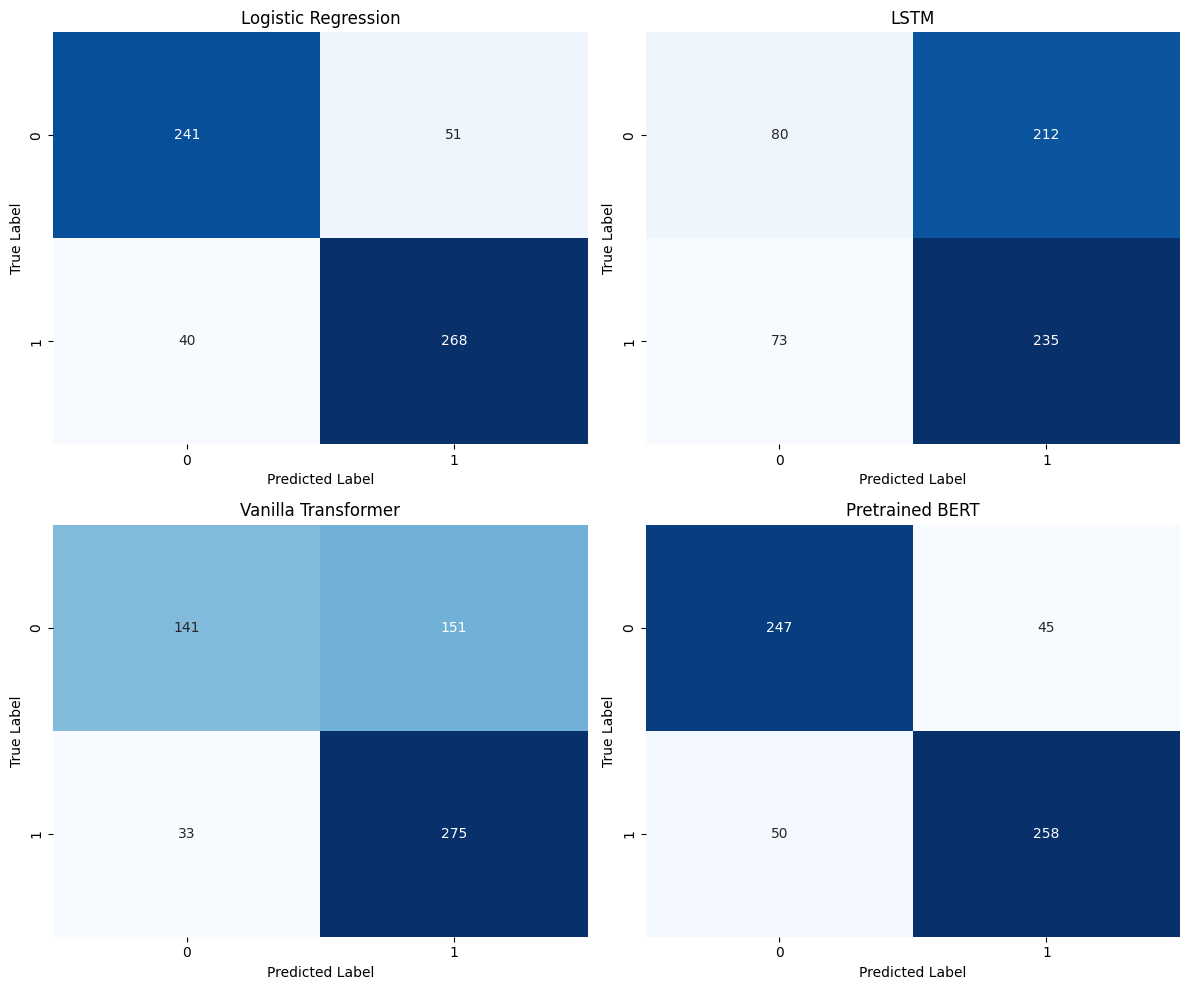

In [14]:
# Comparative Analysis Table
results_data = {
    'Model': ['Logistic Regression', 'LSTM', 'Vanilla Transformer', 'Pretrained BERT'],
    'Accuracy': [lr_acc, lstm_acc, trans_acc, bert_acc],
    'Precision': [lr_precision, lstm_precision, trans_precision, bert_precision],
    'Recall': [lr_recall, lstm_recall, trans_recall, bert_recall],
    'F1-Score': [lr_f1, lstm_f1, trans_f1, bert_f1]
}

results_df = pd.DataFrame(results_data)
display(results_df)

# Plot Confusion Matrices side-by-side
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
preds_list = [y_pred_lr, y_pred_lstm, y_pred_trans, y_pred_bert]
model_names = ['Logistic Regression', 'LSTM', 'Vanilla Transformer', 'Pretrained BERT']

for idx, ax in enumerate(axes.flat):
    cm = confusion_matrix(y_test, preds_list[idx])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(model_names[idx])
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

plt.tight_layout()
plt.show()